**Importing Libraries**

In [3]:
import numpy as np
import pandas as pd

**Importing all Data**

In [4]:
asset_A = pd.read_csv("Fellows_Data/Asset_A.csv")
asset_B = pd.read_csv("Fellows_Data/Asset_B.csv")
asset_C = pd.read_csv("Fellows_Data/Asset_C.csv")
asset_D = pd.read_csv("Fellows_Data/Asset_D.csv")
asset_E = pd.read_csv("Fellows_Data/Asset_E.csv")
asset_F = pd.read_csv("Fellows_Data/Asset_F.csv")
asset_G = pd.read_csv("Fellows_Data/Asset_G.csv")



In [5]:

for df in [asset_A, asset_B, asset_C, asset_D, asset_E, asset_F, asset_G]:
    for col in ["Close/Last", "Open", "High", "Low"]:
        df[col] = df[col].str.replace("$", "").astype(float)


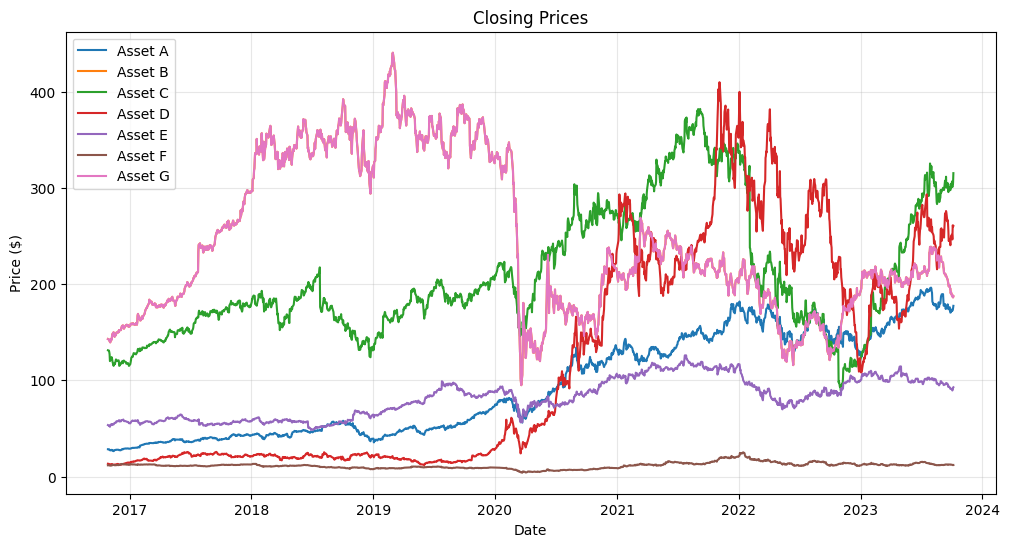

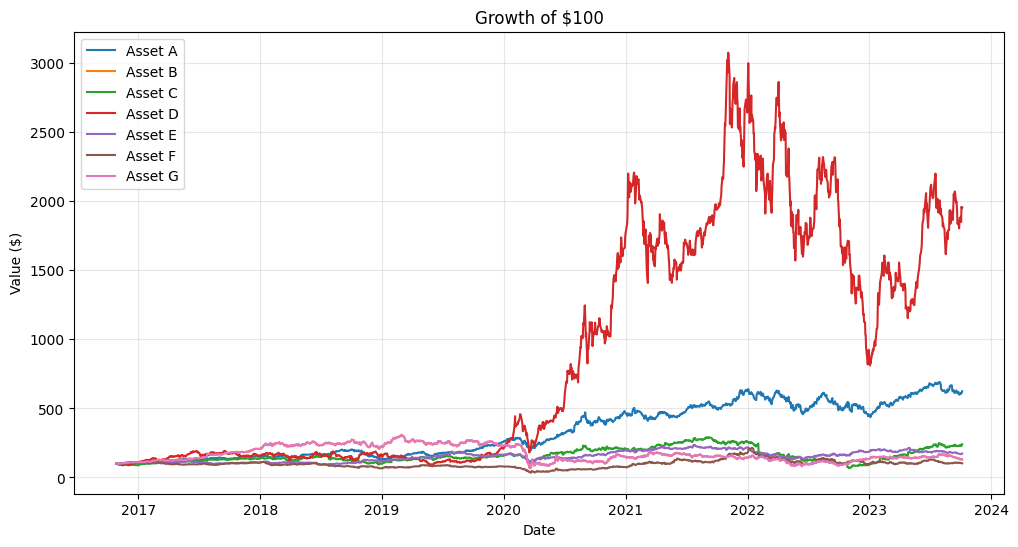

In [6]:
import matplotlib.pyplot as plt

assets = {"A": asset_A, "B": asset_B, "C": asset_C, "D": asset_D,
          "E": asset_E, "F": asset_F, "G": asset_G}

for df in assets.values():
    df["Date"] = pd.to_datetime(df["Date"])

# Plot 1: closing prices
plt.figure(figsize=(12, 6))
for name, df in assets.items():
    plt.plot(df["Date"], df["Close/Last"], label=f"Asset {name}")
plt.title("Closing Prices")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot 2: growth of $100 (every asset starts at 100)
plt.figure(figsize=(12, 6))
for name, df in assets.items():
    plt.plot(df["Date"], df["Close/Last"] / df["Close/Last"].iloc[0] * 100, label=f"Asset {name}")
plt.title("Growth of $100")
plt.xlabel("Date")
plt.ylabel("Value ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Proving Data Set B and G are equal**

In [7]:
import hashlib

# 1. Are the raw files byte-for-byte identical?
hash_B = hashlib.md5(open("Fellows_Data/Asset_B.csv", "rb").read()).hexdigest()
hash_G = hashlib.md5(open("Fellows_Data/Asset_G.csv", "rb").read()).hexdigest()
print("File hash B:", hash_B)
print("File hash G:", hash_G)
print("Files identical:", hash_B == hash_G)

# 2. Are the DataFrames exactly equal (same shape, columns and values)?
print("\nDataFrames equal:", asset_B.equals(asset_G))

# 3. How many cells differ, column by column?
diff = (asset_B != asset_G)
print("\nDifferent cells per column:")
print(diff.sum())
print("Total different cells:", diff.values.sum(), "out of", asset_B.size)


File hash B: 382168f2134188a0d0a35e007aaca708
File hash G: 382168f2134188a0d0a35e007aaca708
Files identical: True

DataFrames equal: True

Different cells per column:
Date          0
Close/Last    0
Volume        0
Open          0
High          0
Low           0
dtype: int64
Total different cells: 0 out of 10476


**Hence deleting Asset G**

In [8]:
del asset_G
assets.pop("G")

print("Remaining assets:", list(assets.keys()))


Remaining assets: ['A', 'B', 'C', 'D', 'E', 'F']


**Creating simple, lag, and log returns**

In [9]:
for name in assets:
    df = assets[name]
    df["close_log_return"] = np.log(df["Close/Last"] / df["Close/Last"].shift(1))
    df["close_simple_return"] = df["Close/Last"].pct_change()
    df["close_log_return_lag_1"] = df["close_log_return"].shift(1)
    assets[name] = df.dropna().copy()

display(assets["A"].head())
display(assets["B"].head())
display(assets["C"].head())
display(assets["D"].head())
display(assets["E"].head())
display(assets["F"].head())



,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1
2,2016-11-01,27.8725,173615040,28.3650,28.4425,27.6325,-0.018220,-0.018055,-0.001584
3,2016-11-02,27.8975,112699920,27.8500,28.0875,27.8075,0.000897,0.000897,-0.018220
4,2016-11-03,27.4575,106154800,27.7450,27.8650,27.3875,-0.015898,-0.015772,0.000897
5,2016-11-04,27.2100,123163720,27.1325,27.5625,27.0275,-0.009055,-0.009014,-0.015898
6,2016-11-07,27.6025,129447720,27.5200,27.6275,27.3650,0.014322,0.014425,-0.009055


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1
2,2016-11-01,142.41,3244187,142.95,143.900,141.8100,-0.000140,-0.000140,-0.004064
3,2016-11-02,140.75,2774119,142.00,142.870,140.5900,-0.011725,-0.011656,-0.000140
4,2016-11-03,140.02,2277503,140.76,140.895,139.3500,-0.005200,-0.005187,-0.011725
5,2016-11-04,139.54,2947947,139.11,140.850,138.8038,-0.003434,-0.003428,-0.005200
6,2016-11-07,143.03,3212041,141.50,143.100,141.4900,0.024703,0.025011,-0.003434


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1
2,2016-11-01,129.50,21974210,131.41,131.9400,128.65,-0.011440,-0.011375,-0.002288
3,2016-11-02,127.17,43895660,130.23,130.2300,126.28,-0.018156,-0.017992,-0.011440
4,2016-11-03,120.00,63660540,122.00,123.2800,119.50,-0.058033,-0.056381,-0.018156
5,2016-11-04,120.75,30468330,119.59,121.9300,119.25,0.006231,0.006250,-0.058033
6,2016-11-07,122.15,22957100,122.83,123.2089,121.35,0.011528,0.011594,0.006231


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1
2,2016-11-01,12.7193,105355057,13.2027,13.2333,12.5403,-0.035732,-0.035101,-0.011262
3,2016-11-02,12.5347,63633718,12.6700,12.8463,12.5003,-0.014620,-0.014513,-0.035732
4,2016-11-03,12.4947,39668230,12.6000,12.7647,12.4693,-0.003196,-0.003191,-0.014620
5,2016-11-04,12.7040,77158686,12.6000,12.8973,12.3973,0.016612,0.016751,-0.003196
6,2016-11-07,12.8807,57865201,12.9060,12.9527,12.6700,0.013813,0.013909,0.016612


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1
2,2016-11-01,52.50,15409130,53.14,53.21,52.085,-0.010799,-0.010741,-0.008630
3,2016-11-02,52.98,10845360,52.34,53.46,52.310,0.009101,0.009143,-0.010799
4,2016-11-03,51.77,21330460,52.99,53.00,51.340,-0.023104,-0.022839,0.009101
5,2016-11-04,52.75,21924610,51.43,53.74,50.840,0.018753,0.018930,-0.023104
6,2016-11-07,54.49,14903780,53.50,54.68,53.190,0.032453,0.032986,0.018753


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1
2,2016-11-01,11.61,35608160,11.78,11.84,11.50,-0.011135,-0.011073,0.001705
3,2016-11-02,11.40,36179870,11.51,11.56,11.36,-0.018253,-0.018088,-0.011135
4,2016-11-03,11.35,38643840,11.39,11.46,11.27,-0.004396,-0.004386,-0.018253
5,2016-11-04,11.34,24724800,11.31,11.50,11.30,-0.000881,-0.000881,-0.004396
6,2016-11-07,11.58,25113380,11.52,11.62,11.39,0.020943,0.021164,-0.000881


**Signals**

In [10]:
for name in assets:
    df = assets[name]
    for col in ["close_log_return"] + [c for c in df.columns if c.startswith("close_log_return_lag_")]:
        df[f"{col}_dir"] = df[col].map(lambda x: 1 if x > 0 else -1)

for name in assets:
    display(assets[name].head())


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1,close_log_return_dir,close_log_return_lag_1_dir
2,2016-11-01,27.8725,173615040,28.3650,28.4425,27.6325,-0.018220,-0.018055,-0.001584,-1,-1
3,2016-11-02,27.8975,112699920,27.8500,28.0875,27.8075,0.000897,0.000897,-0.018220,1,-1
4,2016-11-03,27.4575,106154800,27.7450,27.8650,27.3875,-0.015898,-0.015772,0.000897,-1,1
5,2016-11-04,27.2100,123163720,27.1325,27.5625,27.0275,-0.009055,-0.009014,-0.015898,-1,-1
6,2016-11-07,27.6025,129447720,27.5200,27.6275,27.3650,0.014322,0.014425,-0.009055,1,-1


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1,close_log_return_dir,close_log_return_lag_1_dir
2,2016-11-01,142.41,3244187,142.95,143.900,141.8100,-0.000140,-0.000140,-0.004064,-1,-1
3,2016-11-02,140.75,2774119,142.00,142.870,140.5900,-0.011725,-0.011656,-0.000140,-1,-1
4,2016-11-03,140.02,2277503,140.76,140.895,139.3500,-0.005200,-0.005187,-0.011725,-1,-1
5,2016-11-04,139.54,2947947,139.11,140.850,138.8038,-0.003434,-0.003428,-0.005200,-1,-1
6,2016-11-07,143.03,3212041,141.50,143.100,141.4900,0.024703,0.025011,-0.003434,1,-1


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1,close_log_return_dir,close_log_return_lag_1_dir
2,2016-11-01,129.50,21974210,131.41,131.9400,128.65,-0.011440,-0.011375,-0.002288,-1,-1
3,2016-11-02,127.17,43895660,130.23,130.2300,126.28,-0.018156,-0.017992,-0.011440,-1,-1
4,2016-11-03,120.00,63660540,122.00,123.2800,119.50,-0.058033,-0.056381,-0.018156,-1,-1
5,2016-11-04,120.75,30468330,119.59,121.9300,119.25,0.006231,0.006250,-0.058033,1,-1
6,2016-11-07,122.15,22957100,122.83,123.2089,121.35,0.011528,0.011594,0.006231,1,1


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1,close_log_return_dir,close_log_return_lag_1_dir
2,2016-11-01,12.7193,105355057,13.2027,13.2333,12.5403,-0.035732,-0.035101,-0.011262,-1,-1
3,2016-11-02,12.5347,63633718,12.6700,12.8463,12.5003,-0.014620,-0.014513,-0.035732,-1,-1
4,2016-11-03,12.4947,39668230,12.6000,12.7647,12.4693,-0.003196,-0.003191,-0.014620,-1,-1
5,2016-11-04,12.7040,77158686,12.6000,12.8973,12.3973,0.016612,0.016751,-0.003196,1,-1
6,2016-11-07,12.8807,57865201,12.9060,12.9527,12.6700,0.013813,0.013909,0.016612,1,1


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1,close_log_return_dir,close_log_return_lag_1_dir
2,2016-11-01,52.50,15409130,53.14,53.21,52.085,-0.010799,-0.010741,-0.008630,-1,-1
3,2016-11-02,52.98,10845360,52.34,53.46,52.310,0.009101,0.009143,-0.010799,1,-1
4,2016-11-03,51.77,21330460,52.99,53.00,51.340,-0.023104,-0.022839,0.009101,-1,1
5,2016-11-04,52.75,21924610,51.43,53.74,50.840,0.018753,0.018930,-0.023104,1,-1
6,2016-11-07,54.49,14903780,53.50,54.68,53.190,0.032453,0.032986,0.018753,1,1


,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return,close_log_return_lag_1,close_log_return_dir,close_log_return_lag_1_dir
2,2016-11-01,11.61,35608160,11.78,11.84,11.50,-0.011135,-0.011073,0.001705,-1,1
3,2016-11-02,11.40,36179870,11.51,11.56,11.36,-0.018253,-0.018088,-0.011135,-1,-1
4,2016-11-03,11.35,38643840,11.39,11.46,11.27,-0.004396,-0.004386,-0.018253,-1,-1
5,2016-11-04,11.34,24724800,11.31,11.50,11.30,-0.000881,-0.000881,-0.004396,-1,-1
6,2016-11-07,11.58,25113380,11.52,11.62,11.39,0.020943,0.021164,-0.000881,1,-1


**Price Movements**

In [11]:
summary = pd.concat({
    name: df.groupby("close_log_return_lag_1_dir").aggregate({"close_log_return": ["mean", "count", "sum"]})
    for name, df in assets.items()
})
summary


close_log_return                
                                         mean count       sum
  close_log_return_lag_1_dir                                 
A -1                                 0.001561   812  1.267426
   1                                 0.000607   932  0.565628
B -1                                 0.000062   870  0.053945
   1                                 0.000252   874  0.220343
C -1                                 0.001454   841  1.222960
   1                                -0.000381   903 -0.344144
D -1                                 0.001301   831  1.081112
   1                                 0.002084   913  1.902753
E -1                                 0.000827   838  0.693286
   1                                -0.000148   906 -0.133912
F -1                                -0.000371   900 -0.334300
   1                                 0.000422   844  0.356205

What the results suggest:

A, C and E look mean-reverting. After a down day, the next day was better on average. C and E were even slightly negative after up days. A strategy of buying after down days fits these.
B, D and F look like momentum. After an up day, the next day was better on average. Following yesterday's direction fits these.
The differences are small, about 0.1% per day, so treat them as hints rather than proof.

**Comparing against assets**

Covariance and Correlation.

In [12]:
log_returns = pd.DataFrame({name: df.set_index("Date")["close_log_return"] for name, df in assets.items()})

cov_matrix = log_returns.cov()
corr_matrix = log_returns.corr()

display(cov_matrix.round(6))
display(corr_matrix.round(3))


,A,B,C,D,E,F
A,0.000362,0.000227,0.000277,0.000335,0.000170,0.000168
B,0.000227,0.000799,0.000227,0.000337,0.000252,0.000347
C,0.000277,0.000227,0.000663,0.000331,0.000189,0.000191
D,0.000335,0.000337,0.000331,0.001446,0.000220,0.000297
E,0.000170,0.000252,0.000189,0.000220,0.000315,0.000194
F,0.000168,0.000347,0.000191,0.000297,0.000194,0.000579


,A,B,C,D,E,F
A,1.000,0.423,0.565,0.464,0.504,0.367
B,0.423,1.000,0.312,0.313,0.502,0.511
C,0.565,0.312,1.000,0.338,0.413,0.309
D,0.464,0.313,0.338,1.000,0.326,0.324
E,0.504,0.502,0.413,0.326,1.000,0.455
F,0.367,0.511,0.309,0.324,0.455,1.000


Conclusion:
Correlation runs from -1 to 1. Every pair here is positive and moderate (0.31 to 0.57), so the assets tend to move in the same direction, but loosely.
The most related pair is A and C (0.565). Next come A and E, B and F, and B and E, all around 0.50.
The least related pairs are C with F (0.309), and B with C and B with D (about 0.31). These pairs give the most diversification.

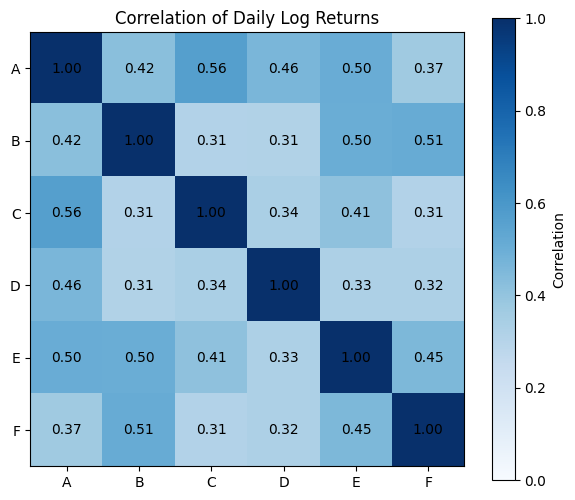

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.imshow(corr_matrix, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_matrix)), corr_matrix.columns)
plt.yticks(range(len(corr_matrix)), corr_matrix.index)
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation of Daily Log Returns")
plt.show()


## Conclusion: Asset Relationships and Strategy Selection

### Summary statistics (daily log returns, Oct 2016 – Oct 2023)

| Asset | Annual return | Annual volatility | Return / volatility | Lag-1 autocorrelation | Behaviour after a down day |
|---|---|---|---|---|---|
| A | 26.4% | 30.2% | 0.88 | -0.094 | Mean-reverting |
| B | 3.9% | 44.9% | 0.09 | +0.053 | Momentum (weak) |
| C | 12.7% | 40.9% | 0.31 | -0.042 | Mean-reverting |
| D | 42.9% | 60.3% | 0.71 | -0.022 | Momentum (weak) |
| E | 8.0% | 28.2% | 0.28 | -0.116 | Mean-reverting |
| F | 0.3% | 38.2% | 0.01 | +0.016 | Momentum (weak) |

Asset G was excluded because it is an exact duplicate of Asset B (identical file hash and values).

### The assets fall into three groups

**Group 1: A, C, E (correlated and mean-reverting)**
- These are the most correlated pairs in the dataset: A–C (0.57), A–E (0.50) and C–E (0.41).
- All three have negative lag-1 autocorrelation, and the groupby analysis shows higher average returns the day after a down day. This makes them suited to a **mean-reversion strategy** (buy after down days).
- The A–C relationship is the most stable, ranging from 0.44 to 0.77 across every year. That makes A–C the best candidate for a **pairs-trading** strategy, which bets on the spread between two related assets returning to normal.
- **Caution:** because they move together, running the same mean-reversion signal on all three is close to one bet placed three times, not three independent bets. Size positions accordingly.

**Group 2: B and F (correlated, weak performers)**
- B–F correlation is 0.51, but it is unstable: it ranges from 0.13 (2017) to 0.68 (2020). That makes it unreliable for pairs trading.
- Both show slight momentum, but have the weakest risk-adjusted returns (0.09 and 0.01). **Neither should be a core holding.** If used at all, it should be as a minor momentum leg.

**Group 3: D (high return, independent)**
- D has the highest return (42.9%) and the highest volatility (60.3%).
- It has the lowest correlation with everything except A (0.31–0.34 with B, C, E and F). This makes it the **strongest diversifier** to pair with Group 1.

### Recommendations

**Consider combining:**
- **A + D:** the two best risk-adjusted assets, with a moderate correlation (0.46).
- **C or E + D:** low correlation (0.33–0.34), and they mix mean-reverting with momentum behaviour.
- **A + C (pairs trade):** a stable, high correlation suits a spread strategy.
- **C + F, B + C, B + D:** the lowest correlations (about 0.31). These are useful for diversification, but B and F weaken returns.

**Avoid:**
- **Treating A, C and E as independent positions.** They share risk and signal.
- **B + F as a pairs trade,** because the correlation is too unstable.
- **Including G** as a separate asset: it duplicates B and would double-count B's risk.

### Caveats
- **Correlations rise in a crisis.** In 2020, almost every pair became more correlated (for example, B–F rose to 0.68 and A–C to 0.77). Diversification is weakest exactly when it is needed most.
- **The effects are small.** The differences in next-day returns are about 0.1% per day, before any transaction costs.
- **All results are in-sample.** They should be validated on data the strategy was not built on, before trading.


**Step 1: Set up with the competition rules**

In [14]:
from backtester import load_data, wide, evaluate_weights, run_simulation, print_metrics, TRADABLE
from strategy import Strategy

data = load_data()
open_px  = wide(data, "Open")[TRADABLE]
close_px = wide(data, "Close")[TRADABLE]
oc_returns = close_px / open_px - 1      # what you actually earn each day

DEV_END = "2021-09-30"        # develop on Oct 2016 – Sep 2021
HOLDOUT_START = "2021-10-01"  # don't touch Oct 2021 – Oct 2023 until Step 6


**Step 2: Baselines, to see what costs do**

In [15]:
def show(weights, label, start=None, end=DEV_END):
    rets, m = evaluate_weights(weights, data, start=start, end=end)
    print(f"{label:<28} Sharpe {m['sharpe']:5.2f}  CAGR {m['cagr']:6.1%}  "
          f"MaxDD {m['max_drawdown']:6.1%}  Active {m['active_days']}")
    return rets, m

equal_long = pd.DataFrame(1/6, index=oc_returns.index, columns=TRADABLE)
show(equal_long, "Equal-weight long, A-F")
show(equal_long * 0.25, "Same at 25% exposure")


Equal-weight long, A-F       Sharpe -1.07  CAGR -19.1%  MaxDD -67.0%  Active 1239
Same at 25% exposure         Sharpe -1.07  CAGR  -4.9%  MaxDD -23.0%  Active 1239


(Date
 2016-10-28   -0.001245
 2016-10-31   -0.002295
 2016-11-01   -0.004363
 2016-11-02   -0.001858
 2016-11-03   -0.003036
                 ...   
 2021-09-24    0.003669
 2021-09-27    0.002018
 2021-09-28   -0.004132
 2021-09-29   -0.001300
 2021-09-30   -0.003175
 Length: 1239, dtype: float64,
 {'sharpe': -1.0689296860849713,
  'cagr': -0.048574160852143944,
  'max_drawdown': -0.23043221442296802,
  'total_return': -0.21715316880406288,
  'daily_vol': 0.00287288200680527,
  'min_equity': 0.7817451859807761,
  'active_days': 1239,
  'avg_gross_exposure': 0.24999999999999994})

**Step 3: Write strategies as functions**

In [16]:
# ---------------------------------------------------------------
# Helper: turn signals (+1 long, -1 short, 0 flat) into valid weights
# ---------------------------------------------------------------
def to_weights(signal):
    signal = signal.fillna(0)
    n = signal.abs().sum(axis=1).replace(0, np.nan)    # how many positions today
    weights = signal.div(n, axis=0).fillna(0)          # split money equally, gross <= 100%
    return weights.shift(1).fillna(0)                  # decide today, trade tomorrow

# ---------------------------------------------------------------
# Building blocks (each one is a "layer")
# ---------------------------------------------------------------
def big_move_fade(threshold=0.03):
    """Mean reversion entry: after a move bigger than threshold, bet on a reversal."""
    return -np.sign(oc_returns) * (oc_returns.abs() > threshold)

def trend_return(days=100):
    """Momentum filter: +1 if price is higher than `days` ago, -1 if lower."""
    return np.sign(close_px / close_px.shift(days) - 1)

def trend_regression(days=60):
    """Momentum filter: sign of the slope of a regression line through log prices."""
    x = np.arange(days)
    x = x - x.mean()
    slope = np.log(close_px).rolling(days).apply(lambda y: (x * (y - y.mean())).sum() / (x ** 2).sum(), raw=True)
    return np.sign(slope)

# ---------------------------------------------------------------
# Strategies
# ---------------------------------------------------------------
def strat_fade_big_moves(threshold=0.03):
    """Mean reversion: fade every big move."""
    return to_weights(big_move_fade(threshold))

def strat_fade_up_only(threshold=0.03):
    """Mean reversion: only short big up days."""
    fade = big_move_fade(threshold)
    return to_weights(fade * (fade < 0))

def strat_fade_down_only(threshold=0.03):
    """Mean reversion: only buy big down days."""
    fade = big_move_fade(threshold)
    return to_weights(fade * (fade > 0))

def strat_bollinger(days=20, n_std=2):
    """Mean reversion: fade prices outside the Bollinger bands."""
    ma = close_px.rolling(days).mean()
    sd = close_px.rolling(days).std()
    z = (close_px - ma) / sd
    return to_weights(-np.sign(z) * (z.abs() > n_std))

def strat_momentum_regression(days=60):
    """Momentum: long if the regression line slopes up, short if down."""
    return to_weights(trend_regression(days))

def strat_pairs(a="Asset_A", b="Asset_C", days=60, entry_z=2):
    """Pairs trading: bet on the gap between two related assets closing."""
    spread = np.log(close_px[a]) - np.log(close_px[b])
    z = (spread - spread.rolling(days).mean()) / spread.rolling(days).std()
    signal = pd.DataFrame(0.0, index=close_px.index, columns=TRADABLE)
    signal[a] = -np.sign(z) * (z.abs() > entry_z)    # gap too wide: short a, long b
    signal[b] = np.sign(z) * (z.abs() > entry_z)
    return to_weights(signal)

def strat_fade_with_trend(threshold=0.03, trend_days=100):
    """Stacked: buy dips in uptrends, short spikes in downtrends."""
    fade = big_move_fade(threshold)
    trend = trend_return(trend_days)
    return to_weights(fade * (np.sign(fade) == trend))

def strat_fade_with_regression_trend(threshold=0.03, trend_days=60):
    """Stacked: same as above, but the trend comes from a regression line."""
    fade = big_move_fade(threshold)
    trend = trend_regression(trend_days)
    return to_weights(fade * (np.sign(fade) == trend))

volume_px = wide(data, "Volume")[TRADABLE]

def strat_fade_trend_volume(threshold=0.03, trend_days=100, volume_mult=1.0):
    """Stacked: big move + agrees with trend + confirmed by high volume."""
    fade = big_move_fade(threshold)                                       # Layer 2: big move
    trend = trend_return(trend_days)                                      # Layer 1: trend
    volume_ratio = volume_px / volume_px.rolling(20).mean().shift(1)      # today's volume vs normal
    signal = fade * (np.sign(fade) == trend) * (volume_ratio > volume_mult)
    return to_weights(signal)

def strat_fade_trend_market(threshold=0.03, trend_days=100, market_days=50):
    """Stacked: big move + asset trend agrees + whole-market trend agrees."""
    fade = big_move_fade(threshold)
    trend = trend_return(trend_days)
    market = close_px.div(close_px.iloc[0]).mean(axis=1)                  # equal-weight "market" index
    market_trend = np.sign(market.pct_change(market_days))
    signal = fade * (np.sign(fade) == trend)
    signal = signal * np.sign(signal).eq(market_trend, axis=0)
    return to_weights(signal)


# ---------------------------------------------------------------
# Run them all on the development period
# ---------------------------------------------------------------
strategies = {
    "Fade big moves":             strat_fade_big_moves(),
    "Fade up days only":          strat_fade_up_only(),
    "Fade down days only":        strat_fade_down_only(),
    "Bollinger bands":            strat_bollinger(),
    "Momentum (regression)":      strat_momentum_regression(),
    "Pairs A-C":                  strat_pairs(),
    "Fade with trend":            strat_fade_with_trend(),
    "Fade with regression trend": strat_fade_with_regression_trend(),
    "Fade + trend + volume":      strat_fade_trend_volume(),
    "Fade + trend + market trend": strat_fade_trend_market()
}

rows = []
for name, w in strategies.items():
    _, m = evaluate_weights(w, data, end=DEV_END)
    rows.append({"strategy": name, "sharpe": m["sharpe"], "cagr": m["cagr"],
                 "max_drawdown": m["max_drawdown"], "active_days": m["active_days"]})
results_dev = pd.DataFrame(rows).set_index("strategy").sort_values("sharpe", ascending=False)
display(results_dev.round(3))

# ---------------------------------------------------------------
# Robustness: does the best idea still work if the settings change?
# ---------------------------------------------------------------
rows = []
for threshold in [0.02, 0.025, 0.03, 0.035, 0.04]:
    for trend_days in [50, 100, 150]:
        _, m = evaluate_weights(strat_fade_with_trend(threshold, trend_days), data, end=DEV_END)
        rows.append({"threshold": threshold, "trend_days": trend_days, "sharpe": m["sharpe"]})
display(pd.DataFrame(rows).pivot(index="threshold", columns="trend_days", values="sharpe").round(2))



,sharpe,cagr,max_drawdown,active_days
strategy,,,,
Fade + trend + market trend,1.421,0.234,-0.144,132
Fade + trend + volume,1.344,0.263,-0.133,160
Fade with regression trend,1.293,0.273,-0.224,236
Fade with trend,1.259,0.257,-0.178,221
Fade up days only,0.934,0.155,-0.140,246
Fade big moves,0.895,0.206,-0.270,442
Fade down days only,0.518,0.087,-0.290,227
Pairs A-C,0.139,0.005,-0.097,133
Bollinger bands,0.034,-0.017,-0.560,596


trend_days,50,100,150
threshold,,,
0.020,0.75,1.13,0.89
0.025,1.14,1.31,1.10
0.030,1.22,1.26,1.03
0.035,1.20,1.03,0.96
0.040,1.10,1.17,1.05


In [20]:
# How did the OTHER five assets move on the same day?
others_move = pd.DataFrame({a: oc_returns.drop(columns=a).mean(axis=1) for a in TRADABLE})

def market_driven_mask(threshold=0.03, others_min=0.01):
    """True when an asset made a big move AND the other five moved >1% the same way."""
    big = oc_returns.abs() > threshold
    same_way = np.sign(others_move) == np.sign(oc_returns)
    return big & same_way & (others_move.abs() > others_min)

def stock_specific_mask(threshold=0.03, others_min=0.01):
    """True when an asset made a big move while the other five stayed roughly flat."""
    return (oc_returns.abs() > threshold) & (others_move.abs() <= others_min)

# --- Test the hypothesis directly: which big moves reverse the next day? (before costs) ---
next_day = oc_returns.shift(-1)                      # ONLY used for this analysis, never in a strategy
fade_return = -np.sign(oc_returns) * next_day        # what fading each move would have earned
dev = oc_returns.index <= DEV_END
rows = []
for name, mask in [("All big moves", oc_returns.abs() > 0.03),
                   ("Market-driven", market_driven_mask()),
                   ("Stock-specific", stock_specific_mask())]:
    r = fade_return[mask & dev[:, None]].stack()
    rows.append({"bucket": name, "count": len(r), "avg_next_day_%": r.mean() * 100, "hit_rate_%": (r > 0).mean() * 100})
display(pd.DataFrame(rows).set_index("bucket").round(2))

# --- Strategy: fade + trend, only market-driven moves ---
def strat_fade_trend_market_driven(threshold=0.03, trend_days=100, others_min=0.01):
    fade = big_move_fade(threshold)
    trend = trend_return(trend_days)
    signal = fade * (np.sign(fade) == trend) * market_driven_mask(threshold, others_min)
    return to_weights(signal)

strategies["Fade + trend + market-driven"] = strat_fade_trend_market_driven()
show(strategies["Fade + trend + market-driven"], "Fade + trend + market-driven")

# --- Final blend ---
final_weights = (
    strategies["Fade + trend + market-driven"]
    + strategies["Fade + trend + volume"]
    + strategies["Fade up days only"]
) / 3
show(final_weights, "FINAL blend (dev period)")


,count,avg_next_day_%,hit_rate_%
bucket,,,
All big moves,674,0.50,55.04
Market-driven,321,0.82,59.19
Stock-specific,305,0.20,51.80


Fade + trend + market-driven Sharpe  1.42  CAGR  19.8%  MaxDD -10.2%  Active 95
FINAL blend (dev period)     Sharpe  1.63  CAGR  21.2%  MaxDD  -7.8%  Active 346


(Date
 2016-10-28    0.000000
 2016-10-31    0.000000
 2016-11-01    0.000000
 2016-11-02    0.000000
 2016-11-03    0.000000
                 ...   
 2021-09-24    0.000000
 2021-09-27   -0.008202
 2021-09-28    0.000000
 2021-09-29    0.000000
 2021-09-30    0.000000
 Length: 1239, dtype: float64,
 {'sharpe': 1.6285266398312246,
  'cagr': 0.21193916858920603,
  'max_drawdown': -0.07813755142943613,
  'total_return': 1.5730449490347178,
  'daily_vol': 0.007723510578321073,
  'min_equity': 0.9567186736216314,
  'active_days': 346,
  'avg_gross_exposure': 0.13478611783696529})

**Step 4: Walk-forward test inside the development period**

In [21]:
dev_dates = oc_returns.loc[:DEV_END].index
n_splits = 4
fold = len(dev_dates) // (n_splits + 1)
test_windows = [(dev_dates[fold*(i+1)], dev_dates[min(fold*(i+2), len(dev_dates)) - 1])
                for i in range(n_splits)]

rows = []
for name, w in strategies.items():
    for i, (s, e) in enumerate(test_windows):
        _, m = evaluate_weights(w, data, start=s, end=e)
        rows.append({"strategy": name, "split": i + 1, "test": f"{s.date()} to {e.date()}",
                     "sharpe": m["sharpe"], "cagr": m["cagr"], "max_dd": m["max_drawdown"]})
wf = pd.DataFrame(rows)
display(wf.round(3))
display(wf.groupby("strategy")[["sharpe", "cagr", "max_dd"]].agg(["mean", "min"]).round(3))


,strategy,split,test,sharpe,cagr,max_dd
0,Fade big moves,1,2017-10-23 to 2018-10-15,-0.643,-0.126,-0.187
1,Fade big moves,2,2018-10-16 to 2019-10-09,0.858,0.142,-0.125
2,Fade big moves,3,2019-10-10 to 2020-10-01,2.589,1.348,-0.128
3,Fade big moves,4,2020-10-02 to 2021-09-24,1.060,0.311,-0.141
4,Fade up days only,1,2017-10-23 to 2018-10-15,0.608,0.053,-0.051
5,Fade up days only,2,2018-10-16 to 2019-10-09,0.713,0.075,-0.080
6,Fade up days only,3,2019-10-10 to 2020-10-01,2.165,0.663,-0.109
7,Fade up days only,4,2020-10-02 to 2021-09-24,1.107,0.263,-0.116
8,Fade down days only,1,2017-10-23 to 2018-10-15,-1.041,-0.168,-0.188
9,Fade down days only,2,2018-10-16 to 2019-10-09,0.583,0.072,-0.106


sharpe          cagr        max_dd       
                               mean    min   mean    min   mean    min
strategy                                                              
Bollinger bands               0.082 -1.197  0.076 -0.190 -0.179 -0.267
Fade + trend + market trend   1.486  0.166  0.394  0.009 -0.074 -0.091
Fade + trend + market-driven  1.463  0.281  0.288  0.016 -0.064 -0.102
Fade + trend + volume         1.248  0.055  0.432  0.000 -0.097 -0.133
Fade big moves                0.966 -0.643  0.419 -0.126 -0.145 -0.187
Fade down days only           0.466 -1.041  0.147 -0.168 -0.155 -0.188
Fade up days only             1.148  0.608  0.263  0.053 -0.089 -0.116
Fade with regression trend    1.316 -0.413  0.450 -0.065 -0.132 -0.186
Fade with trend               1.223  0.149  0.467  0.011 -0.118 -0.178
Momentum (regression)        -1.695 -2.848 -0.155 -0.297 -0.236 -0.315
Pairs A-C                     0.130 -0.212  0.006 -0.011 -0.042 -0.062

Blend: ⅓ fade + trend + market-driven, ⅓ fade + trend + volume, ⅓ fade up days only
Settings: big move > 3%, 100-day trend, others moved > 1%, volume > 1.0× its 20-day average
Development results: Sharpe 1.63, CAGR 21.2%, max drawdown −7.8%, 346 active days

**Step 5: Combine strategies into one portfolio**

In [ ]:
combined = 0.5 * strategies["Momentum 60d"] + 0.5 * strategies["Fade big moves"]
show(combined, "Combined 50/50")


In [ ]:
final = strategies["Fade big moves"]   # or whatever you settle on
show(final, "HOLDOUT", start=HOLDOUT_START, end=None)


In [ ]:
log, m = run_simulation(Strategy(), data, start=HOLDOUT_START)
print_metrics(m, "Day-by-day simulation")


In [22]:
show(final_weights, "FINAL (holdout)", start=HOLDOUT_START, end=None)


FINAL (holdout)              Sharpe -0.27  CAGR  -4.9%  MaxDD -29.1%  Active 192


(Date
 2021-10-01    0.000000
 2021-10-04    0.000000
 2021-10-05    0.000000
 2021-10-06    0.000000
 2021-10-07    0.000000
                 ...   
 2023-10-02    0.000000
 2023-10-03    0.000000
 2023-10-04    0.000000
 2023-10-05   -0.000397
 2023-10-06    0.000000
 Length: 507, dtype: float64,
 {'sharpe': -0.2653206040658013,
  'cagr': -0.048630056331164684,
  'max_drawdown': -0.29057177573477877,
  'total_return': -0.09543223214295626,
  'daily_vol': 0.009265303602236619,
  'min_equity': 0.7923251649784921,
  'active_days': 192,
  'avg_gross_exposure': 0.220249835634451})

In [23]:
# FINAL v2: revised after the holdout showed the short side failed in 2022.
# Chosen using all 7 years, so there is no untouched test data left.
volume_px = wide(data, "Volume")[TRADABLE]

fade = big_move_fade(0.03)
trend = trend_return(100)
volume_ratio = volume_px / volume_px.rolling(20).mean().shift(1)
market_driven = market_driven_mask(0.03, 0.01)

# Buy big dips, only in uptrends, only if confirmed by high volume OR a market-wide move
buy_dips = fade.clip(lower=0) * (trend > 0) * ((volume_ratio > 1.0) | market_driven)
long_dips_weights = to_weights(buy_dips)

final_v2 = 0.5 * long_dips_weights + 0.5 * strategies["Fade + trend + volume"]
show(final_v2, "FINAL v2 (all 7 years)", end=None)

# Year-by-year Sharpe
rets, _ = evaluate_weights(final_v2, data)
yearly = rets.groupby(rets.index.year).apply(lambda r: r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else 0)
display(yearly.round(2).to_frame("sharpe"))


FINAL v2 (all 7 years)       Sharpe  1.16  CAGR  19.1%  MaxDD -13.3%  Active 282


,sharpe
Date,
2016,0.00
2017,-0.28
2018,1.01
2019,0.39
2020,2.51
2021,1.43
2022,0.11
2023,1.44
